Key findings from EDA to consider models:
Nodes are nearly identical
There is a strong daily pattern
All follow the same weekly and holiday behavior as well
Extreme spikes occurred in April–June 2024 and did not repeat in 2025

Will start building a forecasting tool since it can lead naturally to anomaly detection because flag hours where the actual price deviates far from the forecast
Every day, forecast the 24 hourly MDA prices of tomorrow, for each of the 9 nodes. Hourly precision is key
model must be able to analyze and handle seasonality, and have computing, costs and training benefits.
GOAL: What will electricity cost at each Monclova node, for each hour of tomorrow?”
WHY?: Knowing tomorrow’s prices ahead of time lets stakeholders move flexible activities to cheaper hours, plan purchases and bids and prepare for expensive days.
Parameters prediction is based on: Hour, weekday, holiday, historical prices
model type: supervised learning, there are labels, historical data, training and test sets
Important to set safe enviroments for training to avoide leakage
model will pretty much look like: price = long term trend + daily shape + weekly shape + holiday effects + recent price
Type of model: xgboost, a team of decision trees to backup the predictions

What the model may know (no leakage): when forecasting tomorrow, you know prices up to the end of today, so for any hour tomorrow, the price 24 hours earlier is known, as is everything older. All price-based features use lags of 24h or more. A model using “the price 1 hour ago” would look great in testing and be impossible in real use.

Split by time: train Jan 2024 – Mar 2025, test Apr – Jun 2025 (3 months, the full spring season). Caveat to state: the test period has no extreme spikes like 2024’s, so test errors will look better than in a heat-wave year.
The three models:

Naive baseline: tomorrow at hour h = today at hour h (lag_24). The bar to beat, and the production fallback.
XGBoost: one global model for all 9 nodes (node as a feature), using calendar + lag features. Justified by your EDA: the nodes share one signal.
Prophet: one model per node. A fairness detail matters here: plain Prophet would forecast all 3 test months from March 31, a 91-day horizon, while XGBoost forecasts one day ahead. That would be an unfair comparison. The fix: give Prophet the same lag features as extra inputs (add_regressor), so both models work day-ahead with the same information. We’ll do that when we get to Prophet.

Building a baseline as the previos step for modeling, since the data is so similar this will provide a parameter to measure the efficacy of the chosen model 
Modeling cost time to build, run and to mantain production and  knowing if building one is useful with actual data is always beneficial, if the trained model only beats the baseline with a small porcentage then
it is better not to spend on it. If it's actually a good percentage it;s a good way to justify the expense.
Baseline it's also a production fallback in case something is off with the model, baseline can provide contingency data.
We have 0 values, so using MAPE (Mean absolute percentage error)  will break my model percentage manipulation an values dividing by those zeros will give 
undefined data back.

importing libraries, calling the model parameters set on yaml document and the database. Yaml's objective is to set parameters there in case those change so
the code can keep on functioning properly without needing to update it.

In [1]:
import numpy as np
import pandas as pd
import yaml
import holidays
import plotly.express as px

with open("../config.yaml") as f:
    cfg = yaml.safe_load(f)

m_cfg      = cfg["modeling"]
TARGET     = m_cfg["target"]
SPLIT_DATE = pd.Timestamp(m_cfg["split_date"])
PEAK_HOURS = m_cfg["peak_hours"]
LAGS       = m_cfg["lags"]

df = pd.read_parquet("../data/processed/pml_mda.parquet")
df = df.sort_values(["clv_nodo", "timestamp"]).reset_index(drop=True)
print(df.shape, "| split at", SPLIT_DATE.date())

(118152, 8) | split at 2025-04-01


shape of the dataset looks fine, also made sure once more that my dates have such format.
setting up the calendar features and defining separeted lag features per node. Also defining the summary of historical prices.
Grouping price columns by node and looping through the defined lags
Creating roll functions to create a consecutive window of 24 consecutive values (1 day) for mean and max value, since it's the prediction base.
Then will run the functions, retreive the data and add it to the set.

In [2]:
mx_holidays = holidays.Mexico(years=range(2024, 2027))

def add_features(df, lags=LAGS):
    """Calendar + lag features. All price features use data >= 24h old (day-ahead rule)."""
    df = df.sort_values(["clv_nodo", "timestamp"]).copy()
    ts = df["timestamp"]

    df["hour"]       = ts.dt.hour
    df["weekday"]    = ts.dt.day_of_week
    df["month"]      = ts.dt.month
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    df["is_holiday"] = ts.dt.date.isin(mx_holidays).astype(int)

    g = df.groupby("clv_nodo")[TARGET]
    for lag in lags:
        df[f"lag_{lag}"] = g.shift(lag)

    df["roll_mean_24"] = g.transform(lambda s: s.shift(24).rolling(24).mean())
    df["roll_max_24"]  = g.transform(lambda s: s.shift(24).rolling(24).max())
    return df

feat = add_features(df)
feat[["clv_nodo", "timestamp", TARGET, "lag_24", "lag_168", "roll_mean_24"]].head(30)

,clv_nodo,timestamp,pml,lag_24,lag_168,roll_mean_24
0,06AEO-115,2024-01-01 00:00:00,279.92,NaN,NaN,NaN
1,06AEO-115,2024-01-01 01:00:00,279.21,NaN,NaN,NaN
2,06AEO-115,2024-01-01 02:00:00,274.23,NaN,NaN,NaN
3,06AEO-115,2024-01-01 03:00:00,264.01,NaN,NaN,NaN
4,06AEO-115,2024-01-01 04:00:00,243.44,NaN,NaN,NaN
5,06AEO-115,2024-01-01 05:00:00,232.46,NaN,NaN,NaN
6,06AEO-115,2024-01-01 06:00:00,0.00,NaN,NaN,NaN
7,06AEO-115,2024-01-01 07:00:00,0.00,NaN,NaN,NaN
8,06AEO-115,2024-01-01 08:00:00,0.00,NaN,NaN,NaN
9,06AEO-115,2024-01-01 09:00:00,0.00,NaN,NaN,NaN


Noticing some lag columns have no data yet which is normal since this is showing the data from first day and theer is not enough past information yet to 
have actual data, but to be sure I'll check that only the first days have missing data to be sure.

In [3]:
feat[["lag_24", "lag_48", "lag_168", "roll_mean_24", "roll_max_24"]].isna().sum()

lag_24           216
lag_48           432
lag_168         1512
roll_mean_24     423
roll_max_24      423
dtype: int64

Data is looking as expected and making sense but will look further just to make sure

In [4]:
feat[["clv_nodo", "timestamp", TARGET, "lag_24", "lag_168", "roll_mean_24"]].iloc[168:180]

,clv_nodo,timestamp,pml,lag_24,lag_168,roll_mean_24
168,06AEO-115,2024-01-08 00:00:00,409.38,430.77,279.92,508.356250
169,06AEO-115,2024-01-08 01:00:00,381.90,406.40,279.21,503.716250
170,06AEO-115,2024-01-08 02:00:00,368.93,399.80,274.23,500.638750
171,06AEO-115,2024-01-08 03:00:00,345.82,379.98,264.01,498.171667
172,06AEO-115,2024-01-08 04:00:00,345.34,384.54,243.44,496.067917
173,06AEO-115,2024-01-08 05:00:00,359.86,380.11,232.46,493.407083
174,06AEO-115,2024-01-08 06:00:00,406.55,369.25,0.00,489.089583
175,06AEO-115,2024-01-08 07:00:00,442.24,350.97,0.00,481.558750
176,06AEO-115,2024-01-08 08:00:00,448.02,333.91,0.00,476.195417
177,06AEO-115,2024-01-08 09:00:00,389.79,298.06,0.00,471.650833


Spliting the data by time in train and test sets and making sure shapes look accurate. 

In [5]:
FEATURES = ["hour", "weekday", "month", "is_weekend", "is_holiday",
            "lag_24", "lag_48", "lag_168", "roll_mean_24", "roll_max_24"]

feat = feat.dropna(subset=FEATURES).reset_index(drop=True)   # drops the first week of each node

train = feat[feat["timestamp"] <  SPLIT_DATE].copy()
test  = feat[feat["timestamp"] >= SPLIT_DATE].copy()

print("Train:", train["timestamp"].min(), "→", train["timestamp"].max(), "|", len(train), "rows")
print("Test: ", test["timestamp"].min(),  "→", test["timestamp"].max(),  "|", len(test),  "rows")

Train: 2024-01-08 00:00:00 → 2025-03-31 23:00:00 | 96984 rows
Test:  2025-04-01 00:00:00 → 2025-06-30 23:00:00 | 19656 rows


Train and test data seem to have the proper shape. Gave them the common 80/20 ratio
Next, defining evaluating functions so they can be used for every model. Starting by writing scoring rules to evaluate each model. Defining err variable to
check difference between actual value vs predicted one by the model, then pick the peak hours and return a dictionary with scores (mean is the best measure for
this case since data is skewed):
 MAE: Mean absolute error - Some error values will be negative, this is dropping the negative.
 RMSE: Root mean square error - Punishing large errors
 MAE_peak: Peak moments have a bigger money stake, 
Creating a second function  to evaluate by node, taking the test prediction and splits the table per node and computes the three scores and gives them a table format
to compare each since we want to make sure to see how each node is behaving

In [6]:
def evaluate(y_true, y_pred, hours):
    err = y_true - y_pred
    peak = hours.isin(PEAK_HOURS)
    return {
        "MAE":      err.abs().mean(),
        "RMSE":     np.sqrt((err ** 2).mean()),
        "MAE_peak": err[peak].abs().mean(),
    }

def evaluate_by_node(data, pred_col):
    rows = []
    for node, g in data.groupby("clv_nodo"):
        rows.append({"clv_nodo": node, **evaluate(g[TARGET], g[pred_col], g["hour"])})
    rows.append({"clv_nodo": "ALL", **evaluate(data[TARGET], data[pred_col], data["hour"])})
    return pd.DataFrame(rows).set_index("clv_nodo").round(1)

results = {}  

Getting the first scores, this is just a simple prediction, no training, just a simple prediction for each hour based on the day before price at the same hour.

In [7]:
test["pred_naive"] = test["lag_24"]          
results["Naive (yesterday)"] = evaluate_by_node(test, "pred_naive")
results["Naive (yesterday)"]

,MAE,RMSE,MAE_peak
clv_nodo,,,
06AEO-115,169.4,285.8,376.2
06AHM-400,168.2,284.2,374.2
06FRO-115,168.3,284.3,374.4
06GRA-115,169.4,285.9,376.3
06MON-115,168.5,284.5,374.6
06MON-230,168.6,284.7,374.8
06RGS-115,168.9,285.1,375.5
06TKS-115,168.3,284.3,374.5
06XOC-115,169.3,285.7,375.9


Pulling a prediction based on the week now to compare both results and define best baseline to evaluate model.

In [8]:
test["pred_naive_week"] = test["lag_168"]
results["Naive (last week)"] = evaluate_by_node(test, "pred_naive_week")
results["Naive (last week)"]

,MAE,RMSE,MAE_peak
clv_nodo,,,
06AEO-115,206.9,337.8,452.0
06AHM-400,204.5,335.5,448.6
06FRO-115,204.4,335.3,448.9
06GRA-115,206.9,337.9,452.2
06MON-115,205.2,335.9,449.4
06MON-230,205.3,336.1,449.7
06RGS-115,205.7,336.6,450.6
06TKS-115,204.5,335.4,449.0
06XOC-115,206.8,337.6,451.8


In [9]:
comparison = pd.DataFrame({name: res.loc["ALL"] for name, res in results.items()}).T
comparison["MAE_vs_best_%"] = ((comparison["MAE"] / comparison["MAE"].min() - 1) * 100).round(1)
comparison

,MAE,RMSE,MAE_peak,MAE_vs_best_%
Naive (yesterday),168.8,284.9,375.2,0.0
Naive (last week),205.6,336.5,450.2,21.8


Differeence between both tests (24hrs vs a week) is meaningful, hour outperforms week, it has about an 18% better MAE, recent conditions matter more than the longer ones plus results are 
nearly identical when looking at them per node, 
Visualizing the actual vs the naive forecast

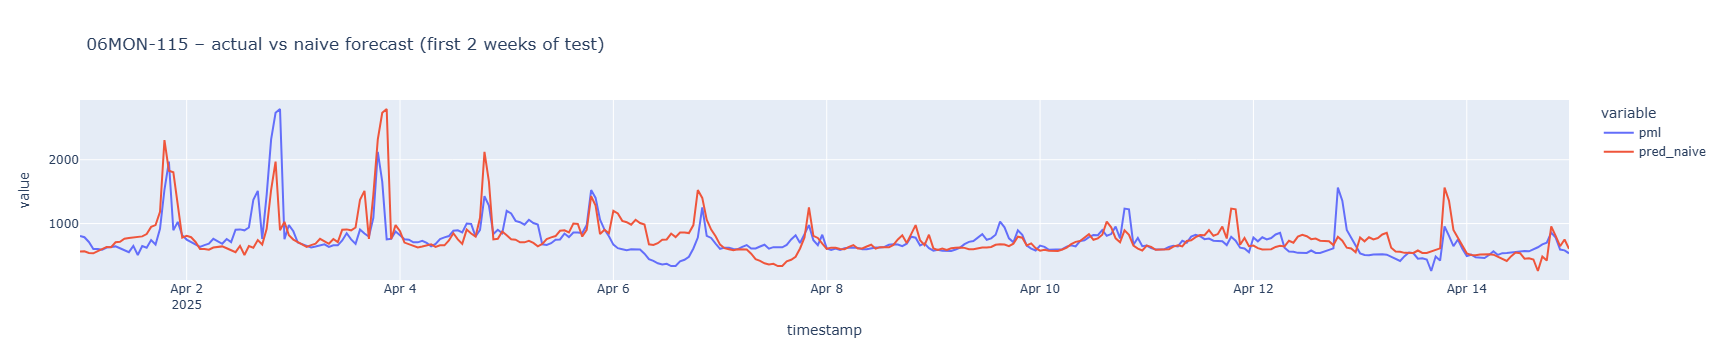

In [10]:
node = "06MON-115"
window = test[(test["clv_nodo"] == node) & (test["timestamp"] < "2025-04-15")]
px.line(window, x="timestamp", y=[TARGET, "pred_naive"],
        title=f"{node} – actual vs naive forecast (first 2 weeks of test)")

We can see that there are some huge gaps particularly during spikes on the naive predictions, it was expected so the model is what we will use to impprove this to get more accurate predictions.
At this point we do know that prices depend on combinations (hours, deay of the week and seasonality), nodes behave similarly, yesterday is a good clue but fails during weekends and holidays,
we have skewed prices and 0 values. 
With this information I can tell that decision trees can iterate through factors combinations and learns best interactions so I don't have to define them.
Since the nodes behave alike, one model is trained on all 9 nodes together, with the node as a feature
Zeros won't affect a tree since they split on thresholds.
To upgrade the tree I will choose XGBoost model so it learns how to autocorrect predictin by using other features. It's fast, feature importance will give the predictions reliability.
CONS: It can't predict prices above what it saw on training sets, no sense of time so it depends fully on feature engineering, doesn't give a range of predicted values.

Starting by adding the node as a feature, each node gets an ID for modeling purposes 

In [11]:
node_map = {node: i for i, node in enumerate(sorted(cfg["nodes"]))}
train["node_id"] = train["clv_nodo"].map(node_map)
test["node_id"]  = test["clv_nodo"].map(node_map)

X_COLS = FEATURES + ["node_id"]
print(node_map)

{'06AEO-115': 0, '06AHM-400': 1, '06FRO-115': 2, '06GRA-115': 3, '06MON-115': 4, '06MON-230': 5, '06RGS-115': 6, '06TKS-115': 7, '06XOC-115': 8}


Pulling the validation set from the training data by using time set from yaml

In [12]:
VAL_START = pd.Timestamp(cfg["modeling"]["val_start"])

fit_set = train[train["timestamp"] <  VAL_START]
val_set = train[train["timestamp"] >= VAL_START]
print(len(fit_set), "rows to learn from |", len(val_set), "rows to validate (March 2025)")

90288 rows to learn from | 6696 rows to validate (March 2025)


Downlading model's library and training data.
Setting a max number of trees so it doesn't iterate forever, adding a small correction to do this carefully, tree can only go 6 layers deep, it can only see 80% of the data (trainning)
Making it stop if at tree 50 there is no improvement

In [13]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=2000,          
    learning_rate=0.05,         
    max_depth=6,                
    subsample=0.8,              
    colsample_bytree=0.8,       
    early_stopping_rounds=50,   
    random_state=42,            
)

xgb.fit(fit_set[X_COLS], fit_set[TARGET],
        eval_set=[(val_set[X_COLS], val_set[TARGET])],
        verbose=100)

print("Trees used:", xgb.best_iteration)

[0]	validation_0-rmse:334.24070
[67]	validation_0-rmse:327.27917
Trees used: 17


In [14]:
test["pred_xgb_sq"] = xgb.predict(test[X_COLS])
results["XGBoost (squared error)"] = evaluate_by_node(test, "pred_xgb_sq")
results["XGBoost (squared error)"].loc[["ALL"]]

,MAE,RMSE,MAE_peak
clv_nodo,,,
ALL,175.3,249.3,305.3


We can see a warning sign here, best point was obtained at tree 17, however from starting point to tree 67 the error barely improved, probably due to rhe 0.05 learning rate parameter, 
so 17 trees are not enough to move from the starting point.
What we know is that the spring spikes pretty much dominante the training data because the default squared-error objective gives very large errors much more weight so the model is putting it's main effort on 
a few spike hrs so learning is not really translating well onto normal hours.
Next step to fix this will be to tell the model to minimize the absolute error rather than the squared one 

In [15]:
xgb_mae = XGBRegressor(
    objective="reg:absoluteerror",   
    eval_metric="mae",               
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=50,
    random_state=42,
)

xgb_mae.fit(fit_set[X_COLS], fit_set[TARGET],
            eval_set=[(val_set[X_COLS], val_set[TARGET])],
            verbose=100)

print("Trees used:", xgb_mae.best_iteration)

[0]	validation_0-mae:306.02298
[92]	validation_0-mae:208.21759
Trees used: 42


Model had a better result with the absolute errors rather than the squared. Best tree is number 42 of the iterations, indicating that is a small model , error fell almost 100 points,
about a third. 
creating a comparison table between these results and the naive prediction

In [16]:
val_naive = evaluate(val_set[TARGET], val_set["lag_24"], val_set["hour"])
val_xgb   = evaluate(val_set[TARGET], xgb_mae.predict(val_set[X_COLS]), val_set["hour"])

val_comparison = pd.DataFrame({"Naive (yesterday)": val_naive, "XGBoost": val_xgb}).T.round(1)
val_comparison["MAE_improvement_%"] = (
    (1 - val_comparison["MAE"] / val_comparison.loc["Naive (yesterday)", "MAE"]) * 100
).round(1)
val_comparison

,MAE,RMSE,MAE_peak,MAE_improvement_%
Naive (yesterday),278.5,390.2,367.8,0.0
XGBoost,206.0,309.0,326.4,26.0


Model is 26% better than the naive predictions but this results are from the validation month March 2025
Testing the model now

In [17]:
test["pred_xgb"] = xgb_mae.predict(test[X_COLS])
results["XGBoost"] = evaluate_by_node(test, "pred_xgb")
results["XGBoost"]

,MAE,RMSE,MAE_peak
clv_nodo,,,
06AEO-115,129.7,234.3,295.1
06AHM-400,128.3,231.8,292.4
06FRO-115,128.6,232.2,293.4
06GRA-115,129.7,234.4,295.3
06MON-115,129.0,232.8,294.2
06MON-230,129.0,232.9,294.3
06RGS-115,129.1,233.2,294.2
06TKS-115,128.8,232.3,293.4
06XOC-115,129.6,234.1,294.9


In [18]:
comparison = pd.DataFrame({name: res.loc["ALL"] for name, res in results.items()}).T

base = comparison.loc["Naive (yesterday)"]
for metric in ["MAE", "RMSE", "MAE_peak"]:
    comparison[f"{metric}_skill_%"] = ((1 - comparison[metric] / base[metric]) * 100).round(1)

comparison.sort_values("MAE")

,MAE,RMSE,MAE_peak,MAE_skill_%,RMSE_skill_%,MAE_peak_skill_%
XGBoost,129.1,233.1,294.1,23.5,18.2,21.6
Naive (yesterday),168.8,284.9,375.2,0.0,0.0,0.0
XGBoost (squared error),175.3,249.3,305.3,-3.9,12.5,18.6
Naive (last week),205.6,336.5,450.2,-21.8,-18.1,-20.0


Scoring the model

In [19]:
side = comparison.loc[["Naive (yesterday)", "XGBoost"], ["MAE", "RMSE", "MAE_peak"]].T
side["Improvement_%"] = ((1 - side["XGBoost"] / side["Naive (yesterday)"]) * 100).round(1)
side

,Naive (yesterday),XGBoost,Improvement_%
MAE,168.8,129.1,23.5
RMSE,284.9,233.1,18.2
MAE_peak,375.2,294.1,21.6


As stated before, improvement percentaje from a model should be decent enough to justify the expenses, test improvement percentage for MAE prediction is 23.5% and for for peak hours (18:00–21:59) 21.6%. 
After aplying XGBoost and changing its objective to absolute error instead of squared error, so it is worth it considering the benefits of this predictionss to the stakeholders.
The test period had no extreme spikes, so errors would be larger in a heat-wave year.
An average miss of 129 against typical prices around 600 is still roughly a 20% error. The forecast is useful for planning, but it isn’t precise.
Viewing the actual predictions of the node for one day

In [20]:
view = test[["clv_nodo", "timestamp", TARGET, "pred_naive", "pred_xgb"]].copy()
view["error_xgb"] = (view[TARGET] - view["pred_xgb"]).round(1)

view[(view["clv_nodo"] == "06MON-115") & (view["timestamp"].dt.date == pd.Timestamp("2025-05-13").date())]

,clv_nodo,timestamp,pml,pred_naive,pred_xgb,error_xgb
63624,06MON-115,2025-05-13 00:00:00,686.82,572.33,588.845642,98.0
63625,06MON-115,2025-05-13 01:00:00,607.00,553.40,590.263550,16.7
63626,06MON-115,2025-05-13 02:00:00,591.50,538.67,590.263550,1.2
63627,06MON-115,2025-05-13 03:00:00,548.85,525.69,576.295654,-27.4
63628,06MON-115,2025-05-13 04:00:00,545.01,521.87,558.099365,-13.1
63629,06MON-115,2025-05-13 05:00:00,556.69,538.08,579.500122,-22.8
63630,06MON-115,2025-05-13 06:00:00,549.01,545.33,589.701477,-40.7
63631,06MON-115,2025-05-13 07:00:00,528.31,542.10,586.497009,-58.2
63632,06MON-115,2025-05-13 08:00:00,542.39,576.05,601.871155,-59.5
63633,06MON-115,2025-05-13 09:00:00,557.06,614.46,615.270447,-58.2


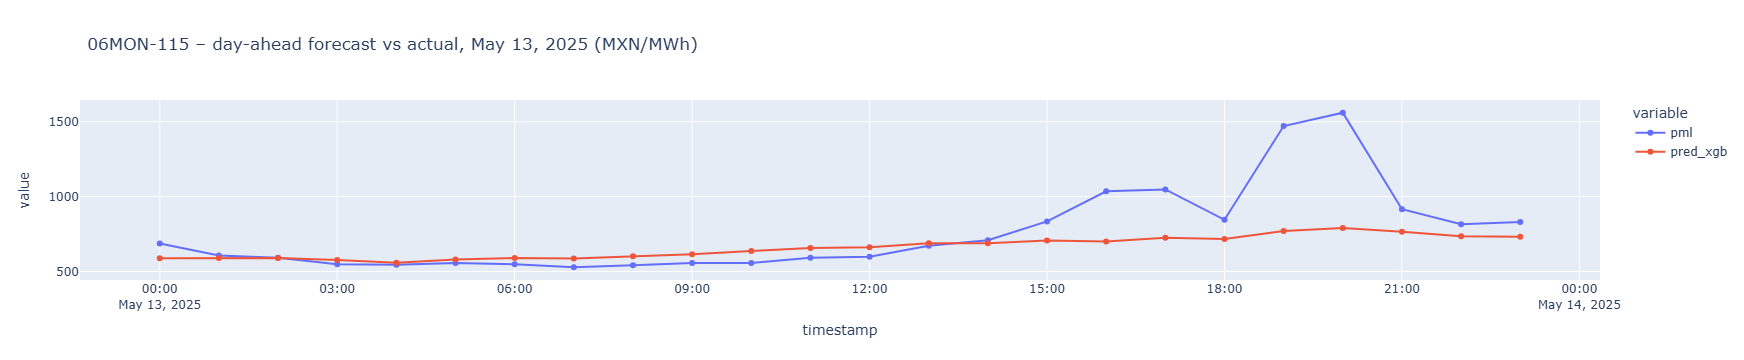

In [21]:
day = view[(view["clv_nodo"] == "06MON-115") &
           (view["timestamp"] >= "2025-05-13") & (view["timestamp"] < "2025-05-14")]

px.line(day, x="timestamp", y=[TARGET, "pred_xgb"], markers=True,
        title="06MON-115 – day-ahead forecast vs actual, May 13, 2025 (MXN/MWh)")

This day is not looking good, prediction is quite flat vs the actual prices. And we know that spike prediction adds more value for stakeholders. Good for regular hours,
not good on evening peaks, which vary a lot from day to day. 
Checking of this day is a bad prediction day or others are behaving like this.

In [22]:
one = test[test["clv_nodo"] == "06MON-115"].copy()
one["abs_err"] = (one[TARGET] - one["pred_xgb"]).abs()

daily_mae = one.groupby(one["timestamp"].dt.date)["abs_err"].mean()
print(daily_mae.describe().round(1))
print("\nMay 13:", round(daily_mae[pd.Timestamp("2025-05-13").date()], 1))
print("\nWorst 5 days:\n", daily_mae.sort_values(ascending=False).head(5).round(1))

count     91.0
mean     129.0
std       86.9
min       29.6
25%       70.1
50%      100.8
75%      153.3
max      523.3
Name: abs_err, dtype: float64

May 13: 139.7

Worst 5 days:
 timestamp
2025-05-20    523.3
2025-05-19    439.9
2025-04-02    356.7
2025-06-11    327.4
2025-05-15    305.5
Name: abs_err, dtype: float64


During this week, evening prices rose well above the previous days, and both forecasts lagged behind because they only know prices that are at least 24 hours old. 
For a stakeholder this means the forecast is dependable in stable periods and should be read with caution when the market is moving fast.
Checking error by hour of the day

In [23]:
print("Mean error:", round((test[TARGET] - test["pred_xgb"]).mean(), 1))
test.assign(abs_err=(test[TARGET] - test["pred_xgb"]).abs()).groupby("hour")["abs_err"].mean().round(0)

Mean error: 36.2


hour
0     126.0
1      89.0
2      87.0
3      73.0
4      73.0
5      82.0
6      78.0
7      58.0
8      61.0
9      68.0
10     80.0
11     88.0
12     90.0
13    111.0
14     99.0
15    130.0
16    141.0
17    126.0
18    140.0
19    357.0
20    413.0
21    267.0
22    146.0
23    115.0
Name: abs_err, dtype: float64

However one of the inconvenients of it is that it only predicts a fixed price per hour, not a range, so this makes the application of the information more rigid for some users.

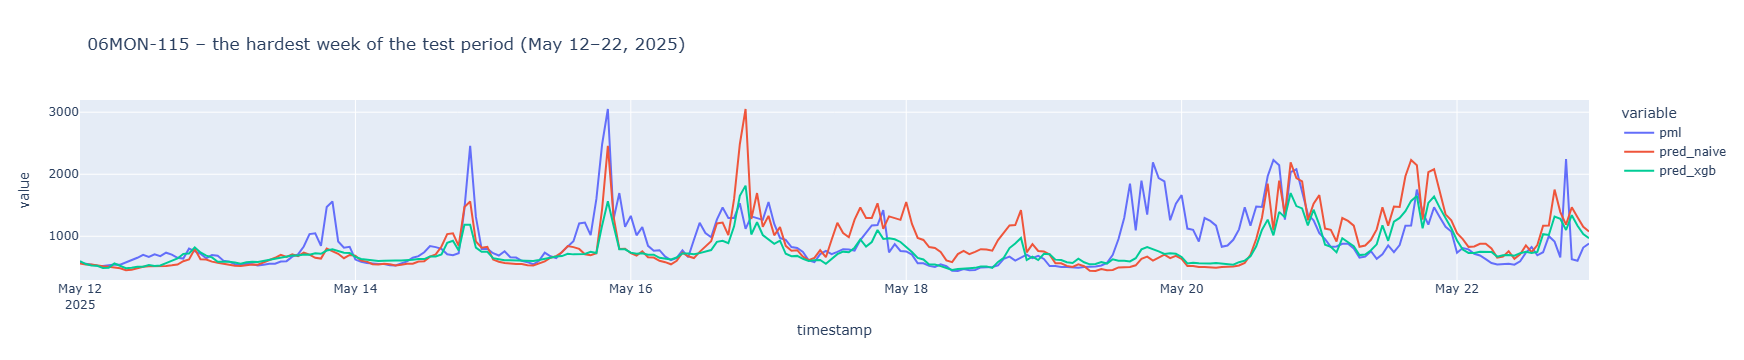

In [24]:
window = one[(one["timestamp"] >= "2025-05-12") & (one["timestamp"] < "2025-05-23")]
px.line(window, x="timestamp", y=[TARGET, "pred_naive", "pred_xgb"],
        title="06MON-115 – the hardest week of the test period (May 12–22, 2025)")

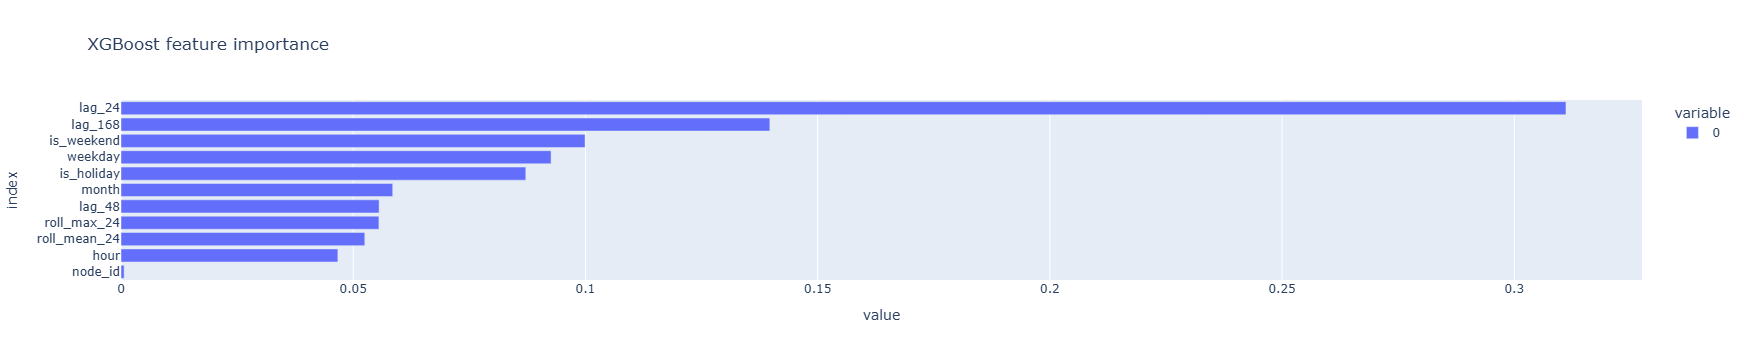

In [25]:
importance = pd.Series(xgb_mae.feature_importances_, index=X_COLS).sort_values()
px.bar(importance, orientation="h", title="XGBoost feature importance")

XGBoost improves on the naive baseline by 23.5% in MAE and 21.6% in peak hours, consistently across validation, test, and all 9 nodes. It is reliable for typical hours 
(errors of 60–90 MXN/MWh in the morning) and weak at 19:00–21:00 (267–413), where it under-predicts. 
The business reading: it supports planning and scheduling decisions today, and its roadmap is clear: add weather and demand inputs, publish a range instead of one number, 
and alert on large deviations.
XGBoost learns rules from a table of clues. Prophet describes the price as a sum of patterns: trend, daily shape, weekly shape, and holidays. If the price were mostly 
regular patterns, Prophet would do well. The comparison tells you whether the patterns or the recent prices carry the information
It offers two things XGBoost lacks: a breakdown of the price into readable components, and a forecast range (lower and upper bound), which is the limitation you noted in your last cell.
it describes the price as a sum of patterns instead of learning rules from a table. It handles one series at a time, so I train one model per node in a loop. 
For a fair comparison it receives the same lagged prices as XGBoost, as extra regressors, so both models forecast one day ahead with the same information. Yearly seasonality is off because 15 months of data cannot establish it.

In [26]:
from prophet import Prophet
print("Prophet ready")

Prophet ready


In [27]:
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

In [28]:
REGRESSORS = ["lag_24", "lag_48", "lag_168", "roll_mean_24", "roll_max_24"]
holiday_df = pd.DataFrame([{"ds": pd.Timestamp(d), "holiday": name} for d, name in mx_holidays.items()])

In [29]:
prophet_parts = []

for node in sorted(cfg["nodes"]):
    tr_n = train[train["clv_nodo"] == node].rename(columns={"timestamp": "ds", TARGET: "y"})
    te_n = test[test["clv_nodo"] == node].rename(columns={"timestamp": "ds"})

    m = Prophet(daily_seasonality=True, weekly_seasonality=True,
                yearly_seasonality=False, holidays=holiday_df)
    for reg in REGRESSORS:
        m.add_regressor(reg)

    m.fit(tr_n[["ds", "y"] + REGRESSORS])
    fc = m.predict(te_n[["ds"] + REGRESSORS])

    part = fc[["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()
    part["clv_nodo"] = node
    prophet_parts.append(part)
    print(node, "done")

prophet_preds = pd.concat(prophet_parts).rename(columns={
    "ds": "timestamp", "yhat": "pred_prophet",
    "yhat_lower": "prophet_lower", "yhat_upper": "prophet_upper"})

test = test.merge(prophet_preds, on=["clv_nodo", "timestamp"], how="left")

C:\Users\zyany\GitHub\CENACE-CHALLENGE\arkham-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
00:49:12 - cmdstanpy - INFO - Chain [1] start processing
00:49:14 - cmdstanpy - INFO - Chain [1] done processing


06AEO-115 done


00:49:15 - cmdstanpy - INFO - Chain [1] start processing
00:49:17 - cmdstanpy - INFO - Chain [1] done processing


06AHM-400 done


00:49:18 - cmdstanpy - INFO - Chain [1] start processing
00:49:20 - cmdstanpy - INFO - Chain [1] done processing


06FRO-115 done


... (8 outputs left out)

00:49:34 - cmdstanpy - INFO - Chain [1] start processing
00:49:36 - cmdstanpy - INFO - Chain [1] done processing


06TKS-115 done


00:49:37 - cmdstanpy - INFO - Chain [1] start processing
00:49:40 - cmdstanpy - INFO - Chain [1] done processing


06XOC-115 done


In [30]:
results["Prophet"] = evaluate_by_node(test, "pred_prophet")
results["Prophet"]

,MAE,RMSE,MAE_peak
clv_nodo,,,
06AEO-115,231.8,298.7,430.2
06AHM-400,230.8,297.1,427.9
06FRO-115,232.5,298.8,429.7
06GRA-115,232.6,299.5,431.0
06MON-115,233.1,299.4,430.8
06MON-230,228.0,295.2,425.5
06RGS-115,230.5,297.4,428.4
06TKS-115,231.9,298.1,429.1
06XOC-115,232.3,299.0,430.3


In [31]:
inside = (test[TARGET] >= test["prophet_lower"]) & (test[TARGET] <= test["prophet_upper"])
print(f"Real price inside Prophet's 80% range: {inside.mean():.1%} of hours")
print("Average range width:", round((test["prophet_upper"] - test["prophet_lower"]).mean()), "MXN/MWh")

Real price inside Prophet's 80% range: 99.8% of hours
Average range width: 2400 MXN/MWh


In [32]:
comparison = pd.DataFrame({name: res.loc["ALL"] for name, res in results.items()}).T

base = comparison.loc["Naive (yesterday)"]
for metric in ["MAE", "RMSE", "MAE_peak"]:
    comparison[f"{metric}_skill_%"] = ((1 - comparison[metric] / base[metric]) * 100).round(1)

comparison.sort_values("MAE")

,MAE,RMSE,MAE_peak,MAE_skill_%,RMSE_skill_%,MAE_peak_skill_%
XGBoost,129.1,233.1,294.1,23.5,18.2,21.6
Naive (yesterday),168.8,284.9,375.2,0.0,0.0,0.0
XGBoost (squared error),175.3,249.3,305.3,-3.9,12.5,18.6
Naive (last week),205.6,336.5,450.2,-21.8,-18.1,-20.0
Prophet,231.5,298.1,429.2,-37.1,-4.6,-14.4


Prophet is the weakest model: MAE 231.5, 37% worse than the naive baseline, consistently across all nodes (228–233). 
Its 80% range contains the real price 99.8% of the time with an average width of about 2,400 MXN/MWh, which is too wide to be useful. 
Two causes: the 2024 heat-wave prices inflate its level and its uncertainty, and its smooth patterns cannot follow day-to-day price changes. Conclusion: in this market, recent prices carry more information than regular patterns.

In [33]:
MODEL_COLS = ["pred_naive", "pred_prophet", "pred_xgb"]

def plot_node(node, start="2025-05-01", end="2025-05-15"):
    w = test[(test["clv_nodo"] == node) & (test["timestamp"] >= start) & (test["timestamp"] < end)]
    return px.line(w, x="timestamp", y=[TARGET] + MODEL_COLS,
                   title=f"{node} – actual vs forecasts ({start} to {end}, MXN/MWh)")

for node in sorted(cfg["nodes"]):
    plot_node(node).show()

The nine charts are nearly identical, as expected from the EDA: the nodes share one price signal, so each model behaves the same way everywhere.
XGBoost follows the actual price most closely in normal hours. The naive forecast has the right shape but arrives one day late. Prophet runs above the actual price most of the time. 
None of the models reaches the height of the sharp evening peaks.
Best performance model is XGBoost
Previosly was mentioned howone of the benefits of choosing XGBoost is that an anomaly detection tool is easy to pull from it, and since it's during anomalies or peaks where
stakeholders find more value, will proceed to configure an anomaly detection tool

In [34]:
# Normal error size per hour of day, from the validation month
val_resid    = val_set[TARGET] - xgb_mae.predict(val_set[X_COLS])
by_hour      = val_resid.groupby(val_set["hour"])
resid_median = by_hour.median()
resid_scale  = by_hour.apply(lambda s: 1.4826 * (s - s.median()).abs().median())

ANOMALY_K = 4   # how many "normal error sizes" away counts as an anomaly

test["resid"]      = test[TARGET] - test["pred_xgb"]
test["z_model"]    = (test["resid"] - test["hour"].map(resid_median)) / test["hour"].map(resid_scale)
test["anom_model"] = test["z_model"].abs() > ANOMALY_K

print(f"Method A flags {test['anom_model'].mean():.2%} of test hours")

Method A flags 1.05% of test hours


In [35]:
def rolling_z(s, days=28):
    med = s.shift(1).rolling(days, min_periods=14).median()
    mad = (s - med).abs().shift(1).rolling(days, min_periods=14).median()
    return (s - med) / (1.4826 * mad)

feat["z_stat"] = feat.groupby(["clv_nodo", "hour"])[TARGET].transform(rolling_z)
test = test.merge(feat[["clv_nodo", "timestamp", "z_stat"]], on=["clv_nodo", "timestamp"], how="left")
test["anom_stat"] = test["z_stat"].abs() > ANOMALY_K

print(f"Method B flags {test['anom_stat'].mean():.2%} of test hours")

Method B flags 1.56% of test hours


Method A uses the XGBoost forecast, and measures each miss against the model’s normal error at that hour of day, learned from the validation month. 
Method B uses no model: it compares each price with the median of the same hour over the previous 28 days. In both, an hour is flagged when it is more than 4 typical deviations away. 
That threshold is a choice, and a lower value would flag more hours.
Saving all data and setting up for a dashboard creation

In [36]:
both   = (test["anom_model"] & test["anom_stat"]).sum()
either = (test["anom_model"] | test["anom_stat"]).sum()
print("Agreement between methods (Jaccard):", round(both / either, 2))

hours_a = test[test["anom_model"]].groupby("timestamp")["clv_nodo"].nunique()
print("Method A – distinct hours flagged:", len(hours_a))
print("Share of those flagged at all 9 nodes:", round((hours_a == 9).mean(), 2))
print("Share of flags above forecast:", round((test.loc[test["anom_model"], "resid"] > 0).mean(), 2))

print("\nDays with most flags (Method A):")
print(test[test["anom_model"]].groupby(test["timestamp"].dt.date).size().sort_values(ascending=False).head(5))

Agreement between methods (Jaccard): 0.27
Method A – distinct hours flagged: 24
Share of those flagged at all 9 nodes: 0.92
Share of flags above forecast: 0.96

Days with most flags (Method A):
timestamp
2025-05-20    57
2025-05-19    36
2025-04-05    27
2025-04-23    18
2025-04-02     9
dtype: int64


In [37]:
node = "06MON-115"
w = test[(test["clv_nodo"] == node) & (test["timestamp"] >= "2025-05-12") & (test["timestamp"] < "2025-05-23")]
fig = px.line(w, x="timestamp", y=[TARGET, "pred_xgb"], title=f"{node} – anomalies flagged by Method A")
fig.add_scatter(x=w.loc[w["anom_model"], "timestamp"], y=w.loc[w["anom_model"], TARGET],
                mode="markers", marker=dict(size=10, color="red"), name="anomaly")
fig.show()

Method A flags 1.05% of test hours and Method B 1.56%. Their agreement is 0.27, which is low, because they answer different questions: A flags what the model could not explain, B flags what is unusual for the past month. 
Method A’s flags are zone-wide events (92% occur at all 9 nodes at once), 96% of flags are above forecast and they concentrate on May 20, May 19, April 5, the same days the forecast error analysis found hardest. Since there are no labeled anomalies, accuracy cannot be measured. 
These checks show the flags are consistent and plausible. In production, Method A would drive alerts, with Method B as a check that does not depend on the model.

In [38]:
from pathlib import Path
out_dir = Path("../data/forecasts")
out_dir.mkdir(parents=True, exist_ok=True)

cols = ["clv_nodo", "timestamp", "hour", TARGET, "pred_naive", "pred_prophet", "pred_xgb",
        "z_model", "anom_model", "anom_stat"]
test[cols].to_parquet(out_dir / "test_predictions.parquet", index=False)
print("Saved", len(test), "rows")

Saved 19656 rows


Selected model: XGBoost with the absolute-error objective. It is the only model that beats the naive baseline on every metric (MAE −23.5%, RMSE −18.2%, peak MAE −21.6%), it is consistent across validation, test, and all nodes, \
it trains in seconds, and one model serves all nine nodes. The naive forecast remains as the production fallback. Known limits: it under-predicts sharp evening peaks and gives a single number, not a range.

BUSINESS VALUE


In [39]:
NODE, RUN_HOURS, LOAD_MW = "06MON-115", 4, 5

def cheapest_start(prices, hours=RUN_HOURS):
    """Start hour of the cheapest block of consecutive hours."""
    return min(range(0, 24 - hours + 1), key=lambda s: prices[s:s + hours].sum())

# A fixed timetable a client could set without any model:
# the cheapest block on average in January-March 2025
recent = train[(train["clv_nodo"] == NODE) & (train["timestamp"] >= "2025-01-01")]
fixed_start = cheapest_start(recent.groupby("hour")[TARGET].mean().values)

rows = []
node_test = test[test["clv_nodo"] == NODE].sort_values("timestamp")
for day, g in node_test.groupby(node_test["timestamp"].dt.date):
    actual, forecast, naive = g[TARGET].values, g["pred_xgb"].values, g["pred_naive"].values
    paid = lambda start: actual[start:start + RUN_HOURS].mean()     # price actually paid
    rows.append({
        "date": day,
        "Evening (18:00-22:00)": paid(18),
        "Business hours (09:00-13:00)": paid(9),
        f"Fixed timetable (start {fixed_start:02d}:00)": paid(fixed_start),
        "Guided by naive forecast": paid(cheapest_start(naive)),
        "Guided by XGBoost forecast": paid(cheapest_start(forecast)),
        "Perfect foresight": paid(cheapest_start(actual)),
    })

sim = pd.DataFrame(rows).set_index("date")
print(len(sim), "days simulated | fixed timetable starts at", f"{fixed_start:02d}:00")

91 days simulated | fixed timetable starts at 02:00


In [40]:
value = sim.mean().to_frame("avg_price_paid")
xgb_price = value.loc["Guided by XGBoost forecast", "avg_price_paid"]

value["xgb_saves_MXN_per_MWh"] = value["avg_price_paid"] - xgb_price
value["xgb_saves_%"] = (1 - xgb_price / value["avg_price_paid"]) * 100
value["saving_over_test_period_MXN"] = value["xgb_saves_MXN_per_MWh"] * LOAD_MW * RUN_HOURS * len(sim)
value.round(1)

,avg_price_paid,xgb_saves_MXN_per_MWh,xgb_saves_%,saving_over_test_period_MXN
Evening (18:00-22:00),1006.7,468.0,46.5,851677.5
Business hours (09:00-13:00),559.5,20.8,3.7,37860.7
Fixed timetable (start 02:00),601.1,62.4,10.4,113545.9
Guided by naive forecast,545.7,7.0,1.3,12708.1
Guided by XGBoost forecast,538.7,0.0,0.0,0.0
Perfect foresight,510.7,-28.0,-5.5,-50883.3


In [41]:
evening = value.loc["Evening (18:00-22:00)", "avg_price_paid"]
perfect = value.loc["Perfect foresight", "avg_price_paid"]
print(f"Share of the best possible saving captured: {(evening - xgb_price) / (evening - perfect):.0%}")

rank_corr = node_test.groupby(node_test["timestamp"].dt.date).apply(
    lambda g: g[TARGET].corr(g["pred_xgb"], method="spearman"))
print(f"Median daily rank agreement between forecast and actual: {rank_corr.median():.2f}")

Share of the best possible saving captured: 94%
Median daily rank agreement between forecast and actual: 0.79


In [42]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
node_test.groupby(node_test["timestamp"].dt.day_name())[TARGET].mean().round(0).reindex(order)

timestamp
Monday       653.0
Tuesday      728.0
Wednesday    773.0
Thursday     734.0
Friday       759.0
Saturday     664.0
Sunday       516.0
Name: pml, dtype: float64